# Atomic form factors and dielectric functions

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/01-structures/02-dielectric.ipynb)

The interaction of light and X-rays with a sample is described by two different, but related quantities in the **udkm1Dsim** package:

* The **atomic form factors** $f(q_z, E)$ and $m(E)$ are properties of the {py:class}`Atom <udkm1Dsim.structures.atoms.Atom>`s.
  They are used by the atomistic X-ray formalisms {py:class}`XrayKin <udkm1Dsim.simulations.xrays.XrayKin>` and {py:class}`XrayDyn <udkm1Dsim.simulations.xrays.XrayDyn>`, which scatter from every atom at its position in a {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`, e.g. for Bragg peaks.
* The **dielectric function**, i.e. the relative permittivity $\varepsilon_{ij}(E)$, is a property of a {py:class}`Layer <udkm1Dsim.structures.layers.Layer>`.
  It is used by all formalisms, which treat a layer as homogeneous medium, e.g. {py:class}`XrayDynMag <udkm1Dsim.simulations.xrays.XrayDynMag>` and the multilayer absorption of {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>`, as well as the light scattering formalisms.

For a layer with the number density $n_a$ of its atoms, both are related by

$$\varepsilon(E) = 1 - \frac{r_e \lambda^2}{\pi} n_a f(E)$$

with the classical electron radius $r_e$ and the wavelength $\lambda$.
Hence, the dielectric function of a layer can be calculated from the form factors of its atoms, but it is never done automatically.
In the optical range, the form factors are not tabulated and the dielectric function is given directly, e.g. by tabulated optical constants.

| quantity | belongs to | given by | used by |
| :--- | :--- | :--- | :--- |
| atomic form factors $f(q_z, E)$, $m(E)$ | {py:class}`Atom <udkm1Dsim.structures.atoms.Atom>`, {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>` | tables of the elements, custom files | {py:class}`XrayKin <udkm1Dsim.simulations.xrays.XrayKin>`, {py:class}`XrayDyn <udkm1Dsim.simulations.xrays.XrayDyn>` |
| dielectric function $\varepsilon_{ij}(E)$ | {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` | {py:class}`Dispersion <udkm1Dsim.structures.dielectric.Dispersion>`s, e.g. from the atoms, tables, or [refractiveindex.info](https://refractiveindex.info) | {py:class}`XrayDynMag <udkm1Dsim.simulations.xrays.XrayDynMag>`, {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>`, light scattering |

This example first introduces the atomic form factors, then the dielectric tensor and its dispersions, and ends with the dielectric function of iron over a broad energy range.

## Setup

Do all necessary imports and settings.

In [1]:
try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[parallel,refractiveindex]
    import udkm1Dsim as ud

import matplotlib.pyplot as plt
import numpy as np

u = ud.u  # import the pint unit registry from udkm1Dsim
%matplotlib inline
u.setup_matplotlib()  # use matplotlib with pint units

## Atomic form factors

### Sources

The energy-dependent atomic form factor

$$f(E) = f_1(E) - i f_2(E)$$

of every {py:class}`Atom <udkm1Dsim.structures.atoms.Atom>` is read from the tables of {cite:t}`chantler2003` by default, or of {cite:t}`henke1993` for `atomic_form_factor_source="henke"`.
Custom tables with the columns of the photon energy in eV, $f_1$, and $f_2$, e.g. from measurements around an absorption edge, are given by `atomic_form_factor_path`.

The magnetic form factor $m(E) = m_1(E) - i m_2(E)$ is read from the tables of [Project Dyna](https://neel.cnrs.fr/spip.php?rubrique1008&lang=en) or from a custom file given by `magnetic_form_factor_path`.
It is zero at all energies, if no magnetic form factors are tabulated for the element.

The sources and the energy ranges of the form factors are displayed with the atom:

In [2]:
Fe = ud.Atom("Fe", magnetization={"r": 1, "phi": 90 * u.deg, "gamma": 90 * u.deg})
Fe

Atom: Iron
ID: Fe
Symbol: Fe
==============================
Atomic form factors: Chantler from 10.69 eV to 30.01 keV
Magnetic form factors: Fe.mf from 31 eV to 100 keV
╔═══════════════╦══════════╦═══════════════════════════════╦════════╗
║ Parameter     ║  Symbol  ║                         Value ║ Unit   ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ atomic_number ║    Z     ║                            26 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass_number   ║    A     ║                         55.84 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass          ║    m     ║                   9.273×10⁻²⁶ ║ kg     ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ ionicity      ║    I     ║                             0 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ magnetization ║    r     ║                             1 ║        ║
║               ║    φ     ║                            90 ║ deg    ║
║               ║    γ     ║                            90 ║ deg    ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ cromer_mann_a ║    a     ║  [11.77, 7.357, 3.522, 2.304] ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ cromer_mann_b ║    b     ║ [4.761, 0.3072, 15.35, 76.88] ║ Å²     ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ cromer_mann_c ║    c     ║                         1.037 ║        ║
╚═══════════════╩══════════╩═══════════════════════════════╩════════╝

The tables of Chantler et al. do not include the white lines of the absorption edges, e.g. of the $L_3$ edge of Fe.
Here, measured atomic form factors of Fe around its $L$ edges are used instead:

In [3]:
Fe_meas = ud.Atom(
    "Fe",
    id="Fe_meas",
    atomic_form_factor_path="../05-xrays/Fe.cf",
    magnetization={"r": 1, "phi": 90 * u.deg, "gamma": 90 * u.deg},
)
print(Fe_meas)

Atom: Iron
ID: Fe_meas
Symbol: Fe
Atomic form factors: Fe.cf from 12.93 eV to 432.9 keV
Magnetic form factors: Fe.mf from 31 eV to 100 keV
╔═══════════════╦══════════╦═══════════════════════════════╦════════╗
║ Parameter     ║  Symbol  ║                         Value ║ Unit   ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ atomic_number ║    Z     ║                            26 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass_number   ║    A     ║                         55.84 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass          ║    m     ║                   9.273×10⁻²⁶ ║ kg     ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ ionicity      ║    I     ║                             0 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ magnetization ║    r     ║                             1 ║        ║
║               ║    

### Energy dependence

The form factors are interpolated linearly for photon energies, which are given as floats in eV, or for any other spectral quantity, e.g. wavelengths:

In [4]:
print(Fe.get_atomic_form_factor(707))
print(Fe.get_atomic_form_factor(1.7537 * u.nm))
print(Fe_meas.get_magnetic_form_factor([705, 707, 709] * u.eV))

(-2.2589414848018485-1.828852808516599j)
(-2.2159798085187967-1.8288929237318245j)
[  3.5479     +0.258222j     9.64362    +5.3737j
 -10.85709677+12.26035484j]


Outside of their tabulated range, the form factors raise an error, which gives the range in the quantity and unit of the request, instead of extrapolating their values:

In [5]:
try:
    Fe.get_atomic_form_factor(800 * u.nm)
except ValueError as e:
    print(e)

The atomic form factor of Fe (Chantler)
is not defined for the wavelength 800 nm,
but only from 0.04131 nm to 116 nm.


### Mixed atoms

The form factors of an {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>` are averaged from its constituents, weighted by their fractions, in their common energy range.

:::{hint}
Dedicated form factors of a mixed atom, e.g. from experimental data, are given by `atomic_form_factor_path` and `magnetic_form_factor_path` or by setting `atomic_form_factor_coeff` and `magnetic_form_factor_coeff`.
:::

In [6]:
Rh = ud.Atom("Rh")
FeRh = ud.AtomMixed("FeRh")
FeRh.add_atom(Fe, 0.5)
FeRh.add_atom(Rh, 0.5)
FeRh

AtomMixed: FeRh
ID: FeRh
Symbol: FeRh
==============================
Atomic form factors: averaged from the constituents from 10.69 eV to 30.01 keV
Magnetic form factors: averaged from the constituents from 31 eV to 10 keV
╔═══════════════╦══════════╦═════════════╦════════╗
║ Parameter     ║  Symbol  ║       Value ║ Unit   ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ atomic_number ║    Z     ║        35.5 ║        ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ mass_number   ║    A     ║       79.38 ║        ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ mass          ║    m     ║ 1.318×10⁻²⁵ ║ kg     ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ ionicity      ║    I     ║           0 ║        ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ magnetization ║    r     ║           0 ║        ║
║               ║    φ     ║           0 ║ deg    ║
║               ║    γ     ║           0 ║ deg    ║
╚═══════════════╩══════════╩═════════════╩════════╝
2 Constituents
atom     fraction
-------  ----------
Iron     50.0 %
Rhodium  50.0 %

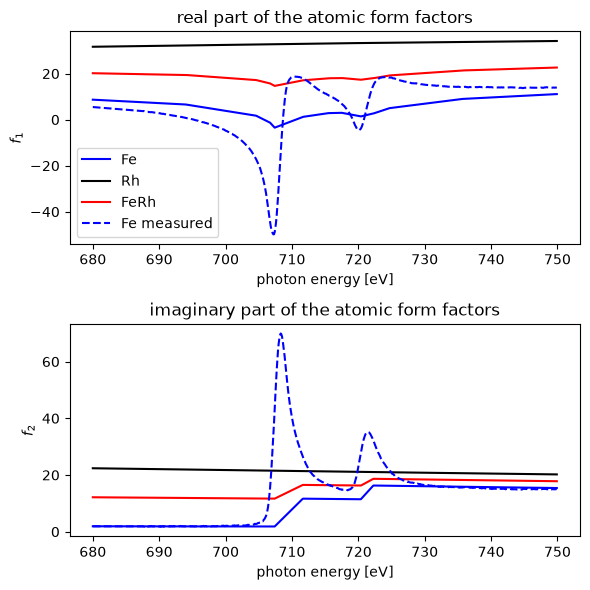

In [7]:
energies = np.r_[680:750:0.1] * u.eV

plt.figure(figsize=[6, 6])
plt.subplot(2, 1, 1)
plt.plot(energies, np.real(Fe.get_atomic_form_factor(energies)), color="b", label="Fe")
plt.plot(energies, np.real(Rh.get_atomic_form_factor(energies)), color="k", label="Rh")
plt.plot(energies, np.real(FeRh.get_atomic_form_factor(energies)), color="r", label="FeRh")
plt.plot(energies, np.real(Fe_meas.get_atomic_form_factor(energies)), "b--", label="Fe measured")
plt.legend()
plt.xlabel("photon energy [eV]")
plt.ylabel("$f_1$")
plt.title("real part of the atomic form factors")

plt.subplot(2, 1, 2)
plt.plot(energies, -np.imag(Fe.get_atomic_form_factor(energies)), color="b")
plt.plot(energies, -np.imag(Rh.get_atomic_form_factor(energies)), color="k")
plt.plot(energies, -np.imag(FeRh.get_atomic_form_factor(energies)), color="r")
plt.plot(energies, -np.imag(Fe_meas.get_atomic_form_factor(energies)), "b--")
plt.xlabel("photon energy [eV]")
plt.ylabel("$f_2$")
plt.title("imaginary part of the atomic form factors")

plt.tight_layout()
plt.show()

### Momentum dependence

For the atomistic X-ray formalisms, the atomic form factor also depends on the momentum transfer $q_z$, which is given by the Cromer-Mann coefficients {cite}`cromermann1968` of the atom, see {py:meth}`get_cm_atomic_form_factor() <udkm1Dsim.structures.atoms.Atom.get_cm_atomic_form_factor>`.
They are part of the `atomic` parameters of the atom.
The dielectric function only uses the forward scattering, i.e. $f(q_z=0, E)$.

In [8]:
qz = np.array([[0, 2, 4]]) / u.angstrom
print(Fe.get_cm_atomic_form_factor(8048 * u.eV, qz))

[[24.83831489-3.18034339j 20.33349038-3.18034339j 15.02628443-3.18034339j]]


## Dielectric tensor

The dielectric tensor, i.e. the relative permittivity tensor, of a layer depends on the photon energy $E$, the strain $\eta$, and the magnetization $\mathbf{m}$.
It is divided into three general terms:

$$\varepsilon_{ij}(E, \eta, \mathbf{m}) = \underbrace{\varepsilon^0_{ij}(E, \eta)}_{\text{non-magnetic}} + \underbrace{\varepsilon^\mathrm{mag}_{ij}(E, \eta, \mathbf{m})}_{\text{magnetic}} + \underbrace{\frac{\mathrm{d}\varepsilon_{ij}}{\mathrm{d}\eta} \eta}_{\text{photoelastic}}$$

with the indices $i, j, k \in \{x, y, z\}$, where $z$ is the surface normal and $yz$ is the scattering plane.

1. **Non-magnetic dielectric function** $\varepsilon^0_{ij}(E, \eta)$:
   It is a 3x3 tensor, which is isotropic for most materials, i.e. $\varepsilon^0_{ij} = \varepsilon^0 \delta_{ij}$, but can also be uniaxial, diagonal, or a full tensor, e.g. for birefringent crystals.
   For an isotropic material with the refractive index $n = n' + i\kappa$, it is $\varepsilon^0 = n^2$, and for X-rays $n = 1 - \delta + i\beta$.
   It is often given by the susceptibility $\chi^0 = \varepsilon^0 - 1$, which is the contribution of the material on top of the vacuum, e.g. from the atomic form factors.
   The imaginary parts of $\varepsilon^0$ and $n$ are positive for absorption.

2. **Magnetic part** $\varepsilon^\mathrm{mag}_{ij}(E, \eta, \mathbf{m}) = -i \varepsilon^m(E, \eta) \epsilon_{ijk} m_k$:
   It is given by the scalar _gyrotropic dielectric function_ $\varepsilon^m$ per unit magnetization, which gives the magneto-optical effects, e.g. the magneto-optical Kerr effect and the X-ray magnetic circular dichroism.
   As an off-diagonal element of the dielectric tensor, it has no vacuum contribution and is equal to the gyrotropic susceptibility $\chi^m$.
   In the optical range, it is often given by the Voigt constant $Q$ as $\varepsilon^m = \varepsilon_{xx} Q$.
   The Levi-Civita symbol $\epsilon_{ijk}$ makes the magnetic part antisymmetric, i.e. its off-diagonal elements change sign for the reversed magnetization.
   $m_k$ are the cartesian components of the magnetization $\mathbf{m}$ of the layer, given by its amplitude $r$, the polar angle $\phi$ from the $z$-axis, and the azimuth $\gamma$ in the $xy$-plane from the $x$-axis.

3. **Photoelastic term** $\frac{\mathrm{d}\varepsilon_{ij}}{\mathrm{d}\eta} \eta$:
   It is the measured, total change of the dielectric tensor per strain, e.g. given by the photoelastic coefficients in the optical range.
   As it already includes the change of the density, it replaces the density scaling of the non-magnetic part.

The strain dependence is handled by the dielectric of the layer for all simulations according to its strain model, while the simulations only account for the change of the thickness of the layer:

* `none`: the dielectric tensor does not depend on the strain.
* `density`: the susceptibilities of the first two terms scale with the density of the layer by $s(\eta) = 1/(1+\eta)$, i.e. $\varepsilon^0_{ij}(E, \eta) = \delta_{ij} + s(\eta) \left(\varepsilon^0_{ij}(E) - \delta_{ij}\right)$ and $\varepsilon^m(E, \eta) = s(\eta) \varepsilon^m(E)$, e.g. for the dielectric from the atomic form factors.
* `photoelastic`: the photoelastic term is added, while the non-magnetic part is not scaled, i.e. $\varepsilon^0_{ij}(E, \eta) = \varepsilon^0_{ij}(E)$.
  As the strain dependence of the magnetic part is rarely known, it still scales with the density by $\varepsilon^m(E, \eta) = s(\eta) \varepsilon^m(E)$.

Written out as tensors, the terms read for a uniaxial material with its c-axis along the surface normal, i.e. with the dielectric functions $\varepsilon^0_\perp$ in the surface plane and $\varepsilon^0_\parallel$ along the surface normal:

$$\varepsilon^0_{ij} = \begin{pmatrix} \varepsilon^0_\perp & 0 & 0 \\ 0 & \varepsilon^0_\perp & 0 \\ 0 & 0 & \varepsilon^0_\parallel \end{pmatrix}$$

$$-i \varepsilon^m \epsilon_{ijk} m_k = \varepsilon^m \begin{pmatrix} 0 & -i m_z & i m_y \\ i m_z & 0 & -i m_x \\ -i m_y & i m_x & 0 \end{pmatrix}$$

with the cartesian components of the magnetization

$$\mathbf{m} = r \begin{pmatrix} \sin\phi \cos\gamma \\ \sin\phi \sin\gamma \\ \cos\phi \end{pmatrix}$$

For an isotropic material ($\varepsilon^0_\perp = \varepsilon^0_\parallel = \varepsilon^0$) with an in-plane magnetization along $y$ ($r = 1$, $\phi = 90°$, $\gamma = 90°$), i.e. in the scattering plane, the unstrained dielectric tensor is

$$\varepsilon = \begin{pmatrix} \varepsilon^0 & 0 & i \varepsilon^m \\ 0 & \varepsilon^0 & 0 \\ -i \varepsilon^m & 0 & \varepsilon^0 \end{pmatrix}$$

The off-diagonal elements change their sign for the reversed magnetization, i.e. $\varepsilon(-\mathbf{m}) = \varepsilon^T(\mathbf{m})$.
This tensor is calculated for Fe at the $L_3$ edge [below](#dielectric_from_atoms).

### Classes and attributes

The dielectric function is organized in two classes:

* A {py:class}`Dispersion <udkm1Dsim.structures.dielectric.Dispersion>` is a single energy-dependent quantity, e.g. a tabulated refractive index, which is evaluated as dielectric function $\varepsilon$.
  Its values are either a scalar or a 3x3 tensor per photon energy.
  They can be given as dielectric function (`kind="eps"`), refractive index (`kind="n"`), $\delta + i\beta$ of X-ray tables (`kind="delta_beta"`), susceptibility (`kind="chi"`), or Voigt constant (`kind="voigt"`), as well as by an optical penetration depth or by mass attenuation coefficients.
* A {py:class}`Dielectric <udkm1Dsim.structures.dielectric.Dielectric>` combines the dispersions of a layer to the dielectric tensor above.
  It is the parameter `dielectric` of the {py:class}`OpticalParameters <udkm1Dsim.structures.parameter_groups.OpticalParameters>` of a layer.

The terms of the dielectric tensor are assigned to the following attributes:

| term | attribute | type |
| :--- | :--- | :--- |
| $\varepsilon^0_{ij}(E)$ | `layer.optical.dielectric.eps0` | {py:class}`Dispersion <udkm1Dsim.structures.dielectric.Dispersion>`, scalar or tensor in the frame of the crystal |
| $\varepsilon^m(E)$ | `layer.optical.dielectric.eps_mag` | {py:class}`Dispersion <udkm1Dsim.structures.dielectric.Dispersion>`, scalar of kind `eps`, `chi`, or `voigt`, optional |
| $R(\theta, \phi, \psi)$ | `layer.optical.dielectric.euler_angles` | z-x-z Euler angles of the crystal, optional, see [below](#euler_angles) |
| $s(\eta)$ | `layer.optical.dielectric.strain_model` | `"none"`, `"density"`, or `"photoelastic"` |
| $\mathrm{d}\varepsilon_{ij}/\mathrm{d}\eta$ | `layer.optical.dielectric.deps_dstrain` | number, tensor, or {py:class}`Dispersion <udkm1Dsim.structures.dielectric.Dispersion>` |
| $\mathbf{m}$ | `layer.magnetic.magnetization` | {py:class}`VectorParameter <udkm1Dsim.structures.parameters.VectorParameter>` of the {py:class}`MagneticParameters <udkm1Dsim.structures.parameter_groups.MagneticParameters>` |
| $\eta$ | given by the simulation, e.g. a `strain_map` | float |

A dispersion itself does not know, whether it is used for the non-magnetic or the gyrotropic part.
Hence, the dielectric evaluates it with the vacuum contribution of its part, i.e. $1$ for `eps0` and $0$ for `eps_mag`.
This matters for susceptibilities, which are converted by $\varepsilon = \chi + 1$ for `eps0`, but $\varepsilon^m = \chi^m$ for `eps_mag`, and for the sum of dispersions.

The dielectric tensor itself is never stored, but calculated by {py:meth}`get_dielectric_tensor() <udkm1Dsim.structures.layers.Layer.get_dielectric_tensor>` of the layer for the actual photon energies, strain, and magnetization of a simulation.

## Dispersions

### Constants

The simplest dispersion is a constant, isotropic refractive index $n = n' + i\kappa$ with $\kappa > 0$ for absorption.
Two or three refractive indices give a uniaxial dispersion, perpendicular and parallel to the c-axis of the crystal, or a diagonal dispersion.

In [9]:
n_iso = ud.Dispersion.from_ref_index(3.7 + 0.01j)
n_uni = ud.Dispersion.from_ref_index([1.76, 1.77])
print(n_iso)
print(n_uni)

Dispersion(n=(3.7+0.01j))
Dispersion(n=[(1.76+0j), (1.77+0j)])


The dielectric function $\varepsilon$ or the susceptibility $\chi = \varepsilon - 1$ is returned for any photon energy.
Floats are taken in eV, while pint quantities can be photon energies, wavelengths, frequencies, or wavenumbers:

In [10]:
print(n_iso.eps(1.55))
print(n_iso.eps(800 * u.nm))
print(n_iso.chi(800 * u.nm))  # susceptibility
print(n_uni.eps(375 * u.THz))

[13.6899+0.074j]
[13.6899+0.074j]
[12.6899+0.074j]
[[[3.0976+0.j 0.    +0.j 0.    +0.j]
  [0.    +0.j 3.0976+0.j 0.    +0.j]
  [0.    +0.j 0.    +0.j 3.1329+0.j]]]


### Tables

Tabulated values are given by {py:meth}`from_array() <udkm1Dsim.structures.dielectric.Dispersion.from_array>` as dielectric function (`kind="eps"`, default), refractive index (`kind="n"`), $\delta + i\beta$ of the refractive index $n = 1 - \delta + i\beta$, e.g. of the X-ray tables of [CXRO](https://henke.lbl.gov/optical_constants/) (`kind="delta_beta"`), susceptibility (`kind="chi"`), or Voigt constant (`kind="voigt"`) for the magnetic part.
Their shape gives the symmetry: `(N,)` isotropic, `(N, 2)` uniaxial, `(N, 3)` diagonal, and `(N, 3, 3)` full tensors.
The values are interpolated linearly.

In [11]:
wavelength = np.r_[400:1001:100] * u.nm
eps_table = ud.Dispersion.from_array(wavelength, np.linspace(5, 2, 7) + 1j * np.linspace(3, 1, 7))
print(eps_table)
print(eps_table.energy_range)

Dispersion(eps: 7 values from 1.24 eV to 3.1 eV, md5=38aee38d)
(np.float64(1.2398419843320025), np.float64(3.0996049608300065))


In [12]:
delta_beta = ud.Dispersion.from_array(
    [700, 710, 720] * u.eV, [3e-3 + 1e-3j, 2e-3 + 4e-3j, 1e-3 + 3e-3j], kind="delta_beta"
)
print(delta_beta.eps(710))

[0.995988+0.007984j]


Tabulated mass attenuation coefficients $\mu/\rho$, e.g. of [NIST](https://www.nist.gov/pml/x-ray-mass-attenuation-coefficients), give only the imaginary part $\beta = \frac{\lambda}{4 \pi} \frac{\mu}{\rho} \rho$ of the refractive index for the density $\rho$ of a layer, see {py:meth}`from_mass_attenuation() <udkm1Dsim.structures.dielectric.Dispersion.from_mass_attenuation>`.
Its real part is set to 1 with a warning.

As the atomic form factors, a dispersion raises an error outside of its energy range instead of extrapolating its values:

In [13]:
try:
    eps_table.chi(1200 * u.nm)
except ValueError as e:
    print(e)

Dispersion(eps: 7 values from 1.24 eV to 3.1 eV, md5=38aee38d)
is not defined for the wavelength 1200 nm,
but only from 400 nm to 1000 nm.
Combine it with another Dispersion by '|' for the missing range.


Text files with the columns of the spectral axis and the real and imaginary part, e.g. `.nk` files or tables of [refractiveindex.info](https://refractiveindex.info), are read by {py:meth}`from_file() <udkm1Dsim.structures.dielectric.Dispersion.from_file>`.
Here, the optical refractive index of chromium is read with the wavelength in µm:

In [14]:
Cr_optical = ud.Dispersion.from_file("Cr.nk", x_unit="um", kind="n")
print(Cr_optical)

Dispersion(n: 49 values from 0.6401 eV to 6.595 eV, source=Cr.nk, md5=2f52cec2)


The files of atomic and magnetic form factors, e.g. `.cf`, `.nff`, or `.mf` files as read by the atoms, are read by {py:meth}`from_form_factors() <udkm1Dsim.structures.dielectric.Dispersion.from_form_factors>` or by `kind="f"` and `kind="m"`.
As the form factors are given per atom or formula unit, e.g. of a compound, they require its `molar_mass` and are evaluated for the density of the layer:

In [15]:
Fe_cf = ud.Dispersion.from_form_factors("../05-xrays/Fe.cf", molar_mass=55.845 * u.g / u.mol)
print(Fe_cf)
print(np.sqrt(Fe_cf.eps(707 * u.eV, density=7874)))  # density in kg/m³

Dispersion(atomic form factors: 916 values from 12.93 eV to 4.329e+05 eV, source=Fe.cf, molar_mass=55.845 g/mol, md5=9bfb1120)
[1.00570723+0.00301537j]


### refractiveindex.info

The [refractiveindex.info](https://refractiveindex.info) database of optical constants {cite}`polyanskiy2024` is accessed by {py:meth}`from_refractiveindex() <udkm1Dsim.structures.dielectric.Dispersion.from_refractiveindex>` with the optional package [refractiveindex](https://github.com/toftul/refractiveindex), which is installed by `pip install udkm1Dsim[refractiveindex]`.
A page of the database is given by its `shelf`, `book`, and `page` or by its `url`.
The database is part of the package, so that no internet connection is needed.

Here, the same data of chromium as in the file above are loaded:

In [16]:
Cr_database = ud.Dispersion.from_refractiveindex(
    url="https://refractiveindex.info/?shelf=main&book=Cr&page=Johnson"
)
print(Cr_database)
print(np.sqrt(Cr_optical.eps(800 * u.nm)), np.sqrt(Cr_database.eps(800 * u.nm)))

Dispersion(eps: 1000 values from 0.6401 eV to 6.595 eV, source=refractiveindex.info v2026-05-24: main/Cr/Johnson, md5=25d83870)
[3.16376821+3.46172093j] [3.16123261+3.46061618j]


Pages are found by `refractiveindex.search()`, e.g. the pages of Fe with an extinction coefficient at 800 nm:

In [17]:
import refractiveindex

refractiveindex.search("Fe", quantity="k", wavelength=800)[:5]

0  main/Fe/Johnson     Johnson and Christy 1974: n,k 0.188–1.94 µm [Experimental data]
1  main/Fe/Werner      Werner et al. 2009: n,k 0.0176–2.48 µm [Experimental data]
2  main/Fe/Ordal       Ordal et al. 1985: n,k 0.667–286 µm [Experimental data]
3  main/Fe/Querry      Querry 1985: n,k 0.21–55.6 µm [Experimental data]
4  main/Fe/Werner-DFT  Werner et al. 2009: DFT calculations; n,k 0.0176–2.48 µm [Models and simulations]

### Combining dispersions

Dispersions are combined by two operators:

* `a | b` is the _fallback_: at every energy `a` is used, where it is defined, and `b` elsewhere.
* `a + b` and `a - b` are the _sum_ and _difference_ of the contributions, e.g. of several oscillators or to subtract a background, i.e. of the susceptibilities $\varepsilon = \varepsilon_a \pm (\varepsilon_b - 1)$ for the non-magnetic part.
* `c * a` _scales_ the contribution by a number `c`, e.g. by the fraction of a phase, i.e. $\varepsilon = 1 + c (\varepsilon_a - 1)$ for the non-magnetic part.

A constant is defined at all energies, so it must be the last one of a fallback, as it would never fall back to the others otherwise.

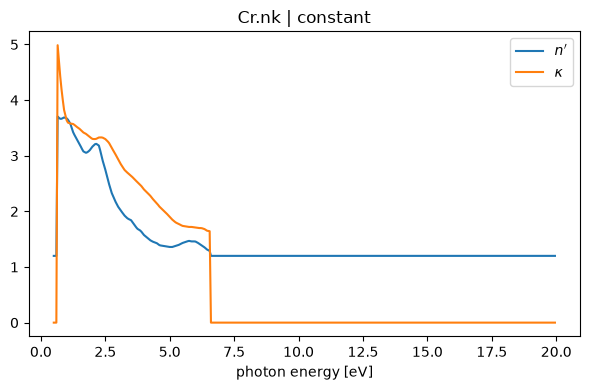

In [18]:
background = ud.Dispersion.from_ref_index(1.2)
Cr_with_background = Cr_optical | background

energy = np.r_[0.5:20:0.05] * u.eV
n = np.sqrt(Cr_with_background.eps(energy))

plt.figure(figsize=[6, 4])
plt.plot(energy, n.real, label=r"$n'$")
plt.plot(energy, n.imag, label=r"$\kappa$")
plt.xlabel("photon energy [eV]")
plt.title("Cr.nk | constant")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
absorption = ud.Dispersion.from_array(None, 0.5j, kind="chi")
print((n_iso + absorption).eps(1.55))  # the susceptibilities are added
print((n_iso - absorption).eps(1.55))  # and subtracted
print((0.5 * n_iso).eps(1.55))  # half of the susceptibility

[13.6899+0.574j]
[13.6899-0.426j]
[7.34495+0.037j]


## Dielectric of a layer

The dielectric is part of the {py:class}`OpticalParameters <udkm1Dsim.structures.parameter_groups.OpticalParameters>` of a layer.
A {py:class}`Dispersion <udkm1Dsim.structures.dielectric.Dispersion>` assigned to it gives the non-magnetic part `eps0`.

In [20]:
SiO2 = ud.Layer(
    "SiO2",
    "SiO2",
    structural=ud.StructuralParameters(thickness=10 * u.nm, density=2200 * u.kg / u.m**3),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(1.45)),
)
SiO2.optical

Parameter,Symbol,Value,Unit
dielectric,ε0,n = 1.45,


In [21]:
SiO2.optical.dielectric = ud.Dispersion.from_ref_index(1.46 + 0.001j)
print(SiO2.optical.dielectric)

ε⁰ = n = 1.46 + 0.001i


### Optical quantities

As the dielectric function depends on the photon energy, all related quantities are given by methods of the layer for any photon energy or wavelength, which also account for the density of the layer:

* {py:meth}`get_dielectric_tensor() <udkm1Dsim.structures.layers.Layer.get_dielectric_tensor>`: dielectric tensor $\varepsilon_{ij}$
* {py:meth}`get_ref_index() <udkm1Dsim.structures.layers.Layer.get_ref_index>`: refractive index $n = n' + i\kappa$
* {py:meth}`get_delta_beta() <udkm1Dsim.structures.layers.Layer.get_delta_beta>`: $\delta$ and $\beta$ of $n = 1 - \delta + i\beta$
* {py:meth}`get_delta_beta_mag() <udkm1Dsim.structures.layers.Layer.get_delta_beta_mag>`: magnetic optical constants $\Delta\delta$ and $\Delta\beta$ of $n_\pm = 1 - (\delta \pm \Delta\delta) + i (\beta \pm \Delta\beta)$
* {py:meth}`get_opt_pen_depth() <udkm1Dsim.structures.layers.Layer.get_opt_pen_depth>`: optical penetration depth or absorption length of the intensity $\zeta = \lambda / (4 \pi \kappa)$
* {py:meth}`get_absorption_coefficient() <udkm1Dsim.structures.layers.Layer.get_absorption_coefficient>`: attenuation coefficient $\mu = 1/\zeta$
* {py:meth}`get_mass_attenuation_coefficient() <udkm1Dsim.structures.layers.Layer.get_mass_attenuation_coefficient>`: mass attenuation coefficient $\mu/\rho$
* {py:meth}`get_critical_angle() <udkm1Dsim.structures.layers.Layer.get_critical_angle>`: critical angle $\theta_c$ of the total external reflection with $\cos\theta_c = n'$
* {py:meth}`get_form_factor() <udkm1Dsim.structures.layers.Layer.get_form_factor>`: effective atomic form factor $f = f_1 - i f_2$ per atom of a layer with atoms

In [22]:
print(SiO2.get_ref_index(800 * u.nm))
print(SiO2.get_opt_pen_depth(800 * u.nm).to("um"))
print(SiO2.get_absorption_coefficient(800 * u.nm))

(1.46+0.001j)
63.66 µm
0.01571 1/µm


### Optical penetration depth

Often, only the optical penetration depth $\zeta$ of the intensity is known for the Lambert-Beer absorption of the {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>` simulation.
As it fixes only the extinction coefficient $\kappa = \lambda / (4 \pi \zeta)$ at every wavelength $\lambda$, it is given by a dispersion with a constant penetration depth and a constant real part $n'$ of the refractive index by {py:meth}`from_opt_pen_depth() <udkm1Dsim.structures.dielectric.Dispersion.from_opt_pen_depth>`:

In [23]:
Cr_pen_depth = ud.Layer(
    "Cr",
    "Cr",
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_opt_pen_depth(15 * u.nm)),
)
print(Cr_pen_depth.get_opt_pen_depth([400, 800] * u.nm).to("nm"))
print(Cr_pen_depth.get_ref_index([400, 800] * u.nm))

[15 15] nm
[1.+2.12206591j 1.+4.24413182j]


For a layer with a dielectric, {py:meth}`set_opt_pen_depth() <udkm1Dsim.structures.layers.Layer.set_opt_pen_depth>` only changes $\kappa$ and keeps the real part $n'$ of its refractive index.
This raises a warning, as it is probably only useful for the Lambert-Beer absorption:

In [24]:
SiO2.set_opt_pen_depth(20 * u.nm)
print(SiO2.get_ref_index(800 * u.nm))
print(SiO2.get_opt_pen_depth(800 * u.nm).to("nm"))
print(SiO2.optical.dielectric)

(1.46+3.183098861837907j)
20 nm
ε⁰ = ζ = 20 nm, n' of (n = 1.46 + 0.001i), else n' = 1


/tmp/ipykernel_175508/4172116425.py:1: UserWarning: The optical penetration depth of the layer 'SiO2' only changes the extinction coefficient kappa, but not the real part n' of its refractive index, so that it is probably only useful for the Lambert-Beer absorption.
  SiO2.set_opt_pen_depth(20 * u.nm)


The dielectric of a layer is never set automatically.
Simulations which need it raise an error with the id of the layer:

In [25]:
empty = ud.Layer("empty", "empty")
try:
    empty.get_ref_index(800 * u.nm)
except ValueError as e:
    print(e)

Layer 'empty': The dielectric is not set. Set it by a Dispersion, e.g. layer.optical.dielectric = Dispersion.from_ref_index(n), or from the atoms of the layer by layer.optical.dielectric = layer.dielectric_from_atoms()!


(dielectric_from_atoms)=
### Dielectric from atoms

For layers with atoms, i.e. {py:class}`AmorphousLayer <udkm1Dsim.structures.layers.AmorphousLayer>` and {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`, the dispersions follow from the atomic and magnetic form factors of their atoms:

$$\varepsilon^0 = 1 + \chi^0 = 1 - \frac{r_e \lambda^2}{\pi} n_a f(E), \quad \varepsilon^m = \chi^m = \frac{r_e \lambda^2}{\pi} n_a m(E)$$

{py:meth}`set_dielectric_from_atoms() <udkm1Dsim.structures.layers.Layer.set_dielectric_from_atoms>` sets both and the strain model `density` as dielectric of the layer, while {py:meth}`dielectric_from_atoms() <udkm1Dsim.structures.layers.Layer.dielectric_from_atoms>` returns it, e.g. to change it before, and {py:meth}`dispersion_from_atoms() <udkm1Dsim.structures.layers.Layer.dispersion_from_atoms>` returns a single dispersion, e.g. to combine it with others.
The dispersions are evaluated for the actual density of the layer in the energy range of the form factors.
Here, the measured atomic form factors of Fe from above are used:

In [26]:
Fe_layer = ud.AmorphousLayer(
    "Fe",
    "Fe",
    atom=Fe_meas,
    structural=ud.StructuralParameters(thickness=5 * u.nm, density=7874 * u.kg / u.m**3),
)
Fe_layer.set_dielectric_from_atoms()
print(Fe_layer.optical.dielectric)

ε⁰ = atomic form factors of Fe_meas from 12.93 eV to 432.9 keV
εᵐ = magnetic form factors of Fe_meas from 31 eV to 100 keV
s(η) = 1/(1+η) for ε⁰ and εᵐ


The dielectric tensor at the Fe $L_3$ edge has the off-diagonal, gyrotropic terms of the magnetization along $y$:

In [27]:
np.set_printoptions(precision=5, suppress=True)
print(Fe_layer.get_dielectric_tensor(707 * u.eV)[0])

[[ 1.01144+0.00607j  0.     -0.j      -0.00126+0.00226j]
 [-0.     +0.j       1.01144+0.00607j  0.     -0.j     ]
 [ 0.00126-0.00226j -0.     +0.j       1.01144+0.00607j]]


The magnetization of the layer is used by default, but can also be given explicitly as amplitude, polar angle $\phi$, and azimuth $\gamma$:

In [28]:
print(Fe_layer.get_dielectric_tensor(707 * u.eV, magnetization=(1, 0, 0))[0])

[[ 1.01144+0.00607j  0.00126-0.00226j  0.     +0.j     ]
 [-0.00126+0.00226j  1.01144+0.00607j  0.     +0.j     ]
 [ 0.     +0.j       0.     +0.j       1.01144+0.00607j]]


For X-rays, the magnetic part is often given by the magnetic optical constants $\Delta\delta$ and $\Delta\beta$ of the refractive indices

$$n_\pm = 1 - (\delta \pm \Delta\delta) + i (\beta \pm \Delta\beta)$$

of the two circular modes along the magnetization, i.e. $\varepsilon^m = 2 (\Delta\delta - i\Delta\beta)$ for $n \approx 1$.
As $\delta$ and $\beta$ are proportional to $f_1$ and $f_2$, $\Delta\delta$ and $\Delta\beta$ are proportional to $m_1$ and $m_2$.
They are given by {py:meth}`get_delta_beta_mag() <udkm1Dsim.structures.layers.Layer.get_delta_beta_mag>` and also as input of the magnetic part by `kind="delta_beta"`:

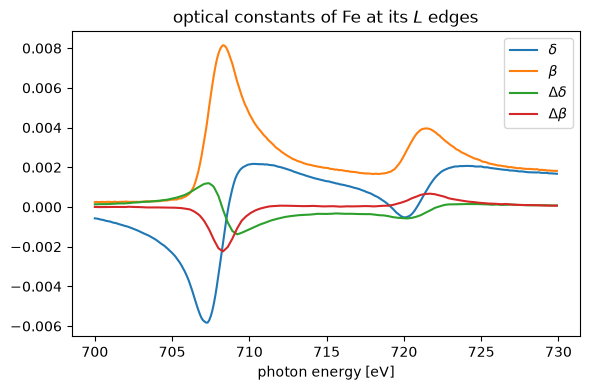

Dispersion(delta_beta: 300 values from 700 eV to 729.9 eV, md5=20c9ff05)


In [29]:
energies = np.r_[700:730:0.1] * u.eV
delta, beta = Fe_layer.get_delta_beta(energies)
delta_mag, beta_mag = Fe_layer.get_delta_beta_mag(energies)

plt.figure(figsize=[6, 4])
plt.plot(energies, delta, label=r"$\delta$")
plt.plot(energies, beta, label=r"$\beta$")
plt.plot(energies, delta_mag, label=r"$\Delta\delta$")
plt.plot(energies, beta_mag, label=r"$\Delta\beta$")
plt.xlabel("photon energy [eV]")
plt.title("optical constants of Fe at its $L$ edges")
plt.legend()
plt.tight_layout()
plt.show()

# the same magnetic part from the tabulated magnetic optical constants
eps_mag = ud.Dispersion.from_array(energies, delta_mag + 1j * beta_mag, kind="delta_beta")
print(eps_mag)

Vice versa, the effective atomic form factor per atom follows from the dielectric function of a layer with atoms, which equals the one of its atom here:

In [30]:
print(Fe_layer.get_form_factor(707 * u.eV))
print(Fe_meas.get_atomic_form_factor(707 * u.eV))

(-48.79799999999942-25.876000000000005j)
(-48.798-25.876j)


The atomic form factors are not tabulated in the optical range.
Hence, they are combined with an optical refractive index as `fallback`, which is appended by `|` as last one:

In [31]:
try:
    Fe_layer.get_ref_index(800 * u.nm)
except ValueError as e:
    print(e)

Fe_layer.set_dielectric_from_atoms(fallback=ud.Dispersion.from_ref_index(2.87 + 3.36j))
print(Fe_layer.get_ref_index(800 * u.nm))
print(Fe_layer.get_ref_index(707 * u.eV))

Layer 'Fe': Dispersion(atomic form factors of Fe_meas: 1, md5=b09c7218)
is not defined for the wavelength 800 nm,
but only from 0.002864 nm to 95.9 nm.
Combine it with another Dispersion by '|' for the missing range.
(2.87+3.36j)
(1.0057072283374764+0.003015374371473527j)


The table of the optical parameters describes the dispersions of the dielectric:

In [32]:
Fe_layer.optical

Optical Parameters
╔═════════════╦══════════╦══════════════════════════════════════════════════════════════════════════════╦════════╗
║ Parameter   ║  Symbol  ║                                                                        Value ║ Unit   ║
╠═════════════╬══════════╬══════════════════════════════════════════════════════════════════════════════╬════════╣
║ dielectric  ║    ε⁰    ║ atomic form factors of Fe_meas from 12.93 eV to 432.9 keV | n = 2.87 + 3.36i ║        ║
║             ║    εᵐ    ║                       magnetic form factors of Fe_meas from 31 eV to 100 keV ║        ║
║             ║   s(η)   ║                                                        1/(1+η) for ε⁰ and εᵐ ║        ║
╚═════════════╩══════════╩══════════════════════════════════════════════════════════════════════════════╩════════╝

As the dispersions are mostly tabulated, their values are only displayed for a given photon energy or wavelength, which is set by the `display_energy` of the dielectric.
It does not change any calculation.
Values close to 1, e.g. for X-rays, are displayed as deviation from 1:

In [33]:
Fe_layer.optical.dielectric.display_energy = 707 * u.eV
Fe_layer.optical

Optical Parameters
╔═════════════╦════════════╦════════════════════════════╦════════╗
║ Parameter   ║   Symbol   ║                      Value ║ Unit   ║
╠═════════════╬════════════╬════════════════════════════╬════════╣
║ dielectric  ║ ε⁰(707 eV) ║  1 + (0.01144 + 0.006065i) ║        ║
║             ║ n(707 eV)  ║ 1 + (0.005707 + 0.003015i) ║        ║
║             ║ εᵐ(707 eV) ║         0.00226 + 0.00126i ║        ║
║             ║    s(η)    ║      1/(1+η) for ε⁰ and εᵐ ║        ║
╚═════════════╩════════════╩════════════════════════════╩════════╝

In [34]:
Fe_layer.optical.dielectric.display_energy = 800 * u.nm
print(Fe_layer.optical.dielectric)
Fe_layer.optical.dielectric.display_energy = None

ε⁰(800 nm) = −3.053 + 19.29i
n(800 nm) = 2.87 + 3.36i
εᵐ(800 nm) = not defined, only from 0.0124 nm to 39.99 nm
s(η) = 1/(1+η) for ε⁰ and εᵐ


For a {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`, the susceptibilities of all its atoms are summed up:

In [35]:
STO = ud.UnitCell("STO", "SrTiO3", c_axis=3.905 * u.angstrom, a_axis=3.905 * u.angstrom)
STO.add_atom(ud.Atom("Sr"), 0)
STO.add_atom(ud.Atom("Ti"), 0.5)
STO.add_atom(ud.Atom("O"), 0.5)
STO.add_atom(ud.Atom("O"), 0.5)
STO.add_atom(ud.Atom("O"), 0)
STO.set_dielectric_from_atoms()
delta, beta = STO.get_delta_beta(8048 * u.eV)
print(f"delta = {delta:.3e}, beta = {beta:.3e}")
print(f"critical angle {STO.get_critical_angle(8048 * u.eV):.3f~P}")
print(f"absorption length {STO.get_opt_pen_depth(8048 * u.eV).to('um'):.3g~P}")
print(f"mass attenuation {STO.get_mass_attenuation_coefficient(8048 * u.eV):.4g~P}")

delta = 1.505e-05, beta = 6.632e-07
critical angle 0.314 deg
absorption length 18.5 µm
mass attenuation 105.7 cm²/g


### Strain

The strain model of the dielectric gives its dependence on the strain $\eta$:

* `none`: no dependence
* `density`: the susceptibilities of the non-magnetic and the magnetic part scale with the density by $s(\eta) = 1/(1+\eta)$, as for the dielectric from atoms
* `photoelastic`: the photoelastic term with the measured, total change $\mathrm{d}\varepsilon/\mathrm{d}\eta$ given by `deps_dstrain` is added to the unscaled non-magnetic part, while the magnetic part still scales with $s(\eta)$

In [36]:
strain = np.linspace(-0.02, 0.02, 5)
photoelastic = ud.Dielectric(
    eps0=ud.Dispersion.from_ref_index(3.7 + 0.01j),
    strain_model="photoelastic",
    deps_dstrain=2 + 0.5j,
)
for eta in strain:
    eps_density = Fe_layer.get_dielectric_tensor(707 * u.eV, eta)[0, 0, 0]
    eps_photoelastic = photoelastic.get_tensor(1.55, eta)[0, 0, 0]
    print(f"strain {eta:+.3f}: density {eps_density:.6f}, photoelastic {eps_photoelastic:.4f}")

strain -0.020: density 1.011671+0.006189j, photoelastic 13.6499+0.0640j
strain -0.010: density 1.011553+0.006126j, photoelastic 13.6699+0.0690j
strain +0.000: density 1.011438+0.006065j, photoelastic 13.6899+0.0740j
strain +0.010: density 1.011325+0.006005j, photoelastic 13.7099+0.0790j
strain +0.020: density 1.011214+0.005946j, photoelastic 13.7299+0.0840j


### Magneto-optics in the optical range

In the optical range, the gyrotropic dispersion is usually given by the Voigt constant $Q$ with $\varepsilon^m = \varepsilon_{xx} Q$:

In [37]:
Ni = ud.Layer(
    "Ni",
    "Ni",
    structural=ud.StructuralParameters(thickness=10 * u.nm, density=8908 * u.kg / u.m**3),
    magnetic=ud.MagneticParameters(magnetization={"r": 1, "phi": 0 * u.deg, "gamma": 0 * u.deg}),
    optical=ud.OpticalParameters(
        dielectric=ud.Dielectric(
            eps0=ud.Dispersion.from_ref_index(2.2 + 4.0j),
            eps_mag=ud.Dispersion.from_array(None, 0.01 - 0.005j, kind="voigt"),
        )
    ),
)
print(Ni.get_dielectric_tensor(800 * u.nm)[0])

[[-11.16  +17.6j      0.2318 +0.0236j  -0.     +0.j    ]
 [ -0.2318 -0.0236j -11.16  +17.6j      0.     +0.j    ]
 [  0.     +0.j      -0.     +0.j     -11.16  +17.6j   ]]


### Anisotropic dielectrics

A uniaxial or full dielectric tensor has no single refractive index.
Only formalisms, which handle anisotropic layers, can use it.

In [38]:
sapphire = ud.Layer(
    "Al2O3",
    "sapphire",
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index([1.760, 1.768])),
)
print(sapphire.get_dielectric_tensor(800 * u.nm)[0])
try:
    sapphire.get_ref_index(800 * u.nm)
except ValueError as e:
    print(e)

[[3.0976 +0.j 0.     +0.j 0.     +0.j]
 [0.     +0.j 3.0976 +0.j 0.     +0.j]
 [0.     +0.j 0.     +0.j 3.12582+0.j]]
Layer 'Al2O3': The dielectric is anisotropic and has no single refractive index. Use get_tensor() instead!


(euler_angles)=
The non-magnetic part is given in the frame of the crystal, which is rotated into the frame of the sample, i.e. with $z$ along the surface normal, by the z-x-z Euler angles $(\theta, \phi, \psi)$ as in PyGTM {cite}`passler2017`:

$$\varepsilon^0 = R \varepsilon^{0\prime} R^T, \quad R = R_z(\phi) R_x(\theta) R_z(\psi)$$

The magnetization and the photoelastic change are given in the frame of the sample and are not rotated.
Here, the c-axis of sapphire is tilted by $\theta = 30°$ from the surface normal, which gives off-diagonal elements:

In [39]:
sapphire.optical.dielectric.euler_angles = (30, 0, 0) * u.deg
print(sapphire.get_dielectric_tensor(800 * u.nm)[0])
sapphire.optical.dielectric.display_energy = 800 * u.nm
sapphire.optical

[[ 3.0976 +0.j  0.     +0.j  0.     +0.j]
 [ 0.     +0.j  3.10466+0.j -0.01222+0.j]
 [ 0.     +0.j -0.01222+0.j  3.11877+0.j]]


Optical Parameters
╔═════════════╦═══════════════╦══════════════════════════════╦════════╗
║ Parameter   ║    Symbol     ║                        Value ║ Unit   ║
╠═════════════╬═══════════════╬══════════════════════════════╬════════╣
║ dielectric  ║ ε⁰ₓₓ(800 nm)  ║                        3.098 ║        ║
║             ║ ε⁰_yy(800 nm) ║                        3.105 ║        ║
║             ║ ε⁰_yz(800 nm) ║                     −0.01222 ║        ║
║             ║ ε⁰_zy(800 nm) ║                     −0.01222 ║        ║
║             ║ ε⁰_zz(800 nm) ║                        3.119 ║        ║
║             ║       R       ║ Euler (z-x-z): (30°, 0°, 0°) ║        ║
╚═════════════╩═══════════════╩══════════════════════════════╩════════╝

## Broadband dielectric function

Finally, the dielectric function of iron is given from the infrared to the soft X-ray range.
The optical constants of {cite:t}`werner2009` from refractiveindex.info are used up to 70 eV and the measured atomic form factors above:

In [40]:
Fe_optical = ud.Dispersion.from_refractiveindex("main", "Fe", "Werner")
Fe_layer.optical.dielectric.eps0 = Fe_optical | Fe_layer.dispersion_from_atoms()
print(Fe_layer.optical.dielectric)

ε⁰ = table of ε: 1000 values from 0.5 eV to 70.5 eV (refractiveindex.info: main/Fe/Werner) | atomic form factors of Fe_meas from 12.93 eV to 432.9 keV
εᵐ = magnetic form factors of Fe_meas from 31 eV to 100 keV
s(η) = 1/(1+η) for ε⁰ and εᵐ


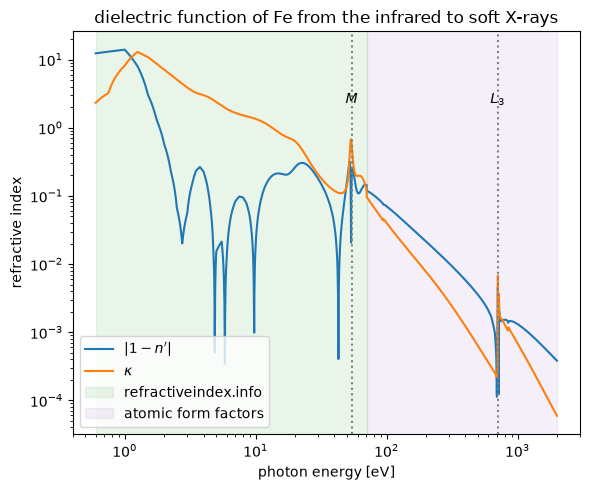

In [41]:
energy = np.geomspace(0.6, 2000, 2000) * u.eV
n = Fe_layer.get_ref_index(energy)
E_optical = Fe_optical.energy_range[1] * u.eV  # highest energy of the optical constants

plt.figure(figsize=[6, 5])
plt.loglog(energy, np.abs(1 - n.real), label=r"$|1 - n'|$")
plt.loglog(energy, n.imag, label=r"$\kappa$")
plt.axvspan(energy[0], E_optical, color="C2", alpha=0.1, label="refractiveindex.info")
plt.axvspan(E_optical, energy[-1], color="C4", alpha=0.1, label="atomic form factors")
for edge, label in [(54 * u.eV, "$M$"), (707 * u.eV, "$L_3$")]:
    plt.axvline(edge, color="gray", ls=":")
    plt.text(edge, 2, label, ha="center", va="bottom")
plt.xlabel("photon energy [eV]")
plt.ylabel("refractive index")
plt.title("dielectric function of Fe from the infrared to soft X-rays")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()